In [1]:
%%bash
pip install -q python-docx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 1.8 MB/s eta 0:00:00


In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

#  download sample image to work with
url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg'
urllib.request.urlretrieve(url, 'sample_image.jpg')

# Load image and convert to RGB
img = cv2.imread('sample_image.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("Sample image loaded successfully!")

Sample image loaded successfully!


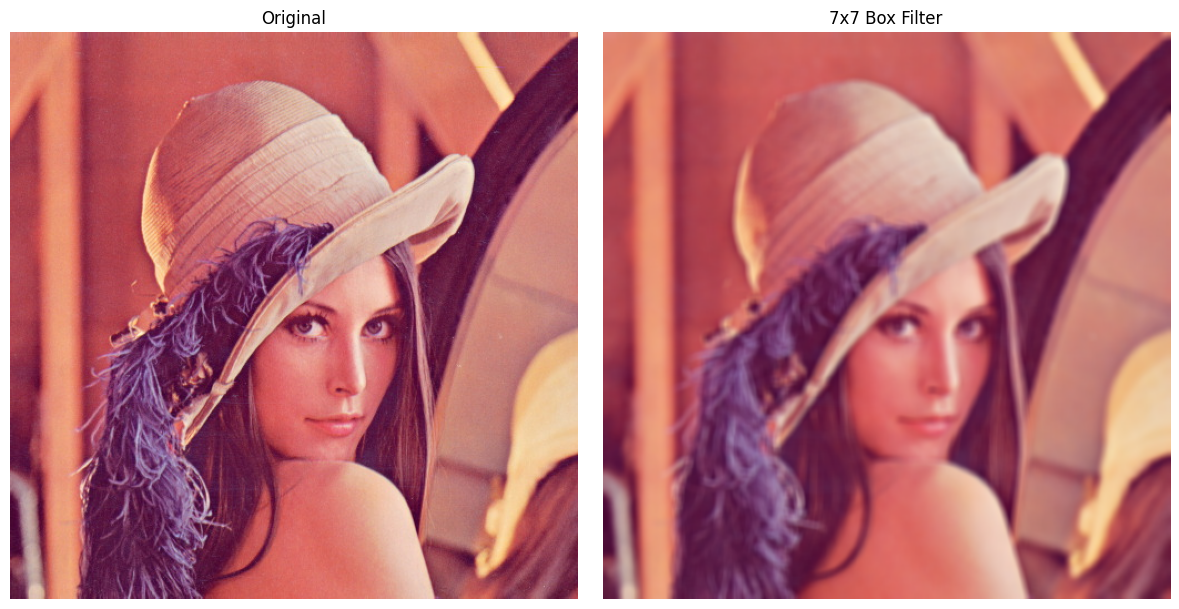

In [7]:
# Task 1: 7x7 Box Filter smoothing
kernel_size = (7, 7)
smoothed_img = cv2.blur(img_rgb, kernel_size)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img_rgb)
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(smoothed_img)
axes[1].set_title("7x7 Box Filter")
axes[1].axis('off')

plt.tight_layout()
plt.show()

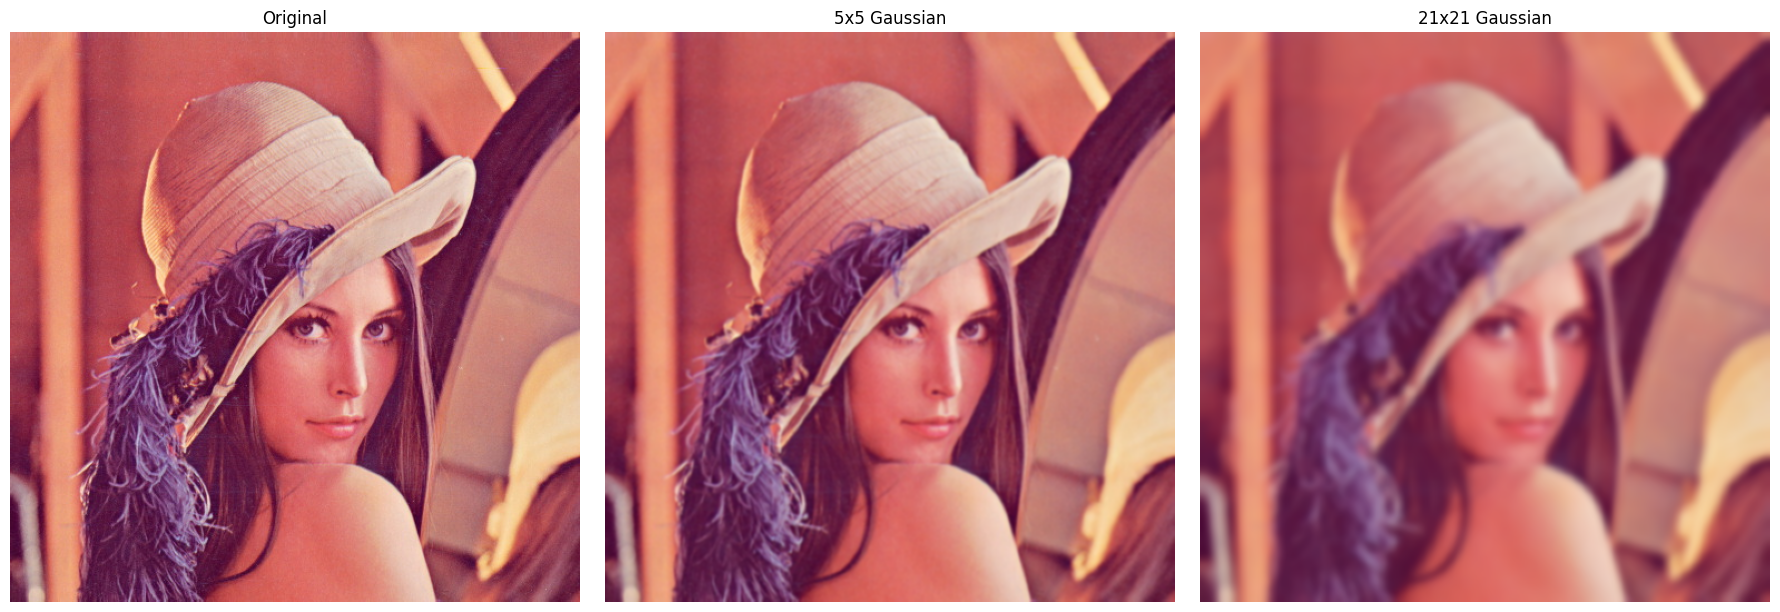

In [8]:
# Task 2: 5x5 vs 21x21 Gaussian Filter
gaussian_5x5 = cv2.GaussianBlur(img_rgb, (5, 5), 0)
gaussian_21x21 = cv2.GaussianBlur(img_rgb, (21, 21), 0)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(img_rgb)
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(gaussian_5x5)
axes[1].set_title("5x5 Gaussian")
axes[1].axis('off')

axes[2].imshow(gaussian_21x21)
axes[2].set_title("21x21 Gaussian")
axes[2].axis('off')

plt.tight_layout()
plt.show()

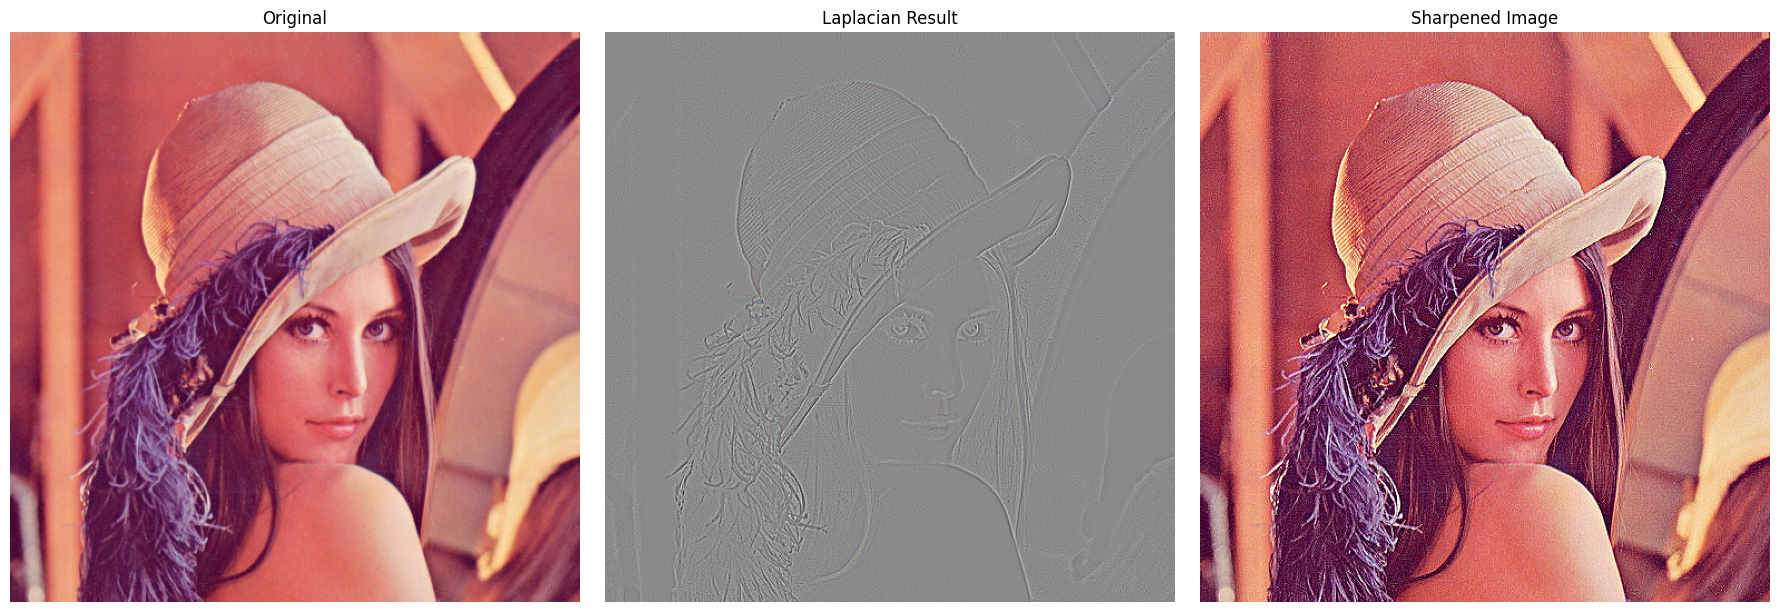

In [9]:
# Task 3: Laplacian Sharpening
# Convert to float32
img_float = img_rgb.astype(np.float32) / 255.0

# Apply 3x3 Laplacian filter
laplacian = cv2.Laplacian(img_float, cv2.CV_32F)

# Sharpen the image
sharpened_img = np.clip(img_float - laplacian, 0.0, 1.0)

# Normalize for visualization
laplacian_vis = np.clip((laplacian - laplacian.min()) / (laplacian.max() - laplacian.min()), 0, 1)

# Plot results
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(img_rgb)
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(laplacian_vis)
axes[1].set_title("Laplacian Result")
axes[1].axis('off')

axes[2].imshow(sharpened_img)
axes[2].set_title("Sharpened Image")
axes[2].axis('off')

plt.tight_layout()
plt.show()